# Customer Churn — In-Class Assignment
## This week: CRISP-DM Phase 2 — Data Understanding

### Learning goal
Develop a defensible understanding of the churn dataset **before changing the data or building a model**.

By the end of the session you should be able to:
- explain what the dataset represents;
- identify the target variable and calculate the churn rate;
- explain the business meaning of churn and class imbalance;
- explain why actual churners can easily be missed;
- explore relationships between customer characteristics and churn;
- identify data-quality concerns;
- formulate evidence-based findings and questions for the next CRISP-DM phases.

### Boundary for this week
**Do not clean, transform, encode, scale, impute, delete rows, engineer features or build a model.**

You may identify possible data-quality issues, but you leave the original dataset unchanged.

## 1. Business context

The company wants to understand customer churn.

A customer with `Churned = 1` has left the company.  
A customer with `Churned = 0` has remained.

Before predicting churn, management needs to understand:
1. How large is the churn problem?
2. What characteristics distinguish churners from non-churners?
3. Which patterns deserve further investigation?
4. What limitations or quality concerns exist in the available data?

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("in_class_customer_churn_dataset.csv")
df.head()

,Customer_ID,Age,Gender,Region,Tenure_Months,Annual_Spend,Promo_Used,Customer_Service_Calls,Churned
0,1,56,Female,South,58,2393.95,1,3,0
1,2,69,Male,South,28,4853.96,1,4,0
2,3,46,Male,North,36,4569.16,1,4,0
3,4,32,Male,East,26,3768.50,1,1,0
4,5,60,Male,South,8,2867.84,1,3,0


## 2. Understand the structure

Answer after running the cells:
- What does one row represent?
- What does one column represent?
- How many customers and variables are present?
- Which column is an identifier?
- Which column is the business outcome/target?

In [5]:
print("Shape:", df.shape)
df.info()

Shape: (300, 9)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             300 non-null    int64  
 1   Age                     300 non-null    int64  
 2   Gender                  300 non-null    str    
 3   Region                  300 non-null    str    
 4   Tenure_Months           300 non-null    int64  
 5   Annual_Spend            300 non-null    float64
 6   Promo_Used              300 non-null    int64  
 7   Customer_Service_Calls  300 non-null    int64  
 8   Churned                 300 non-null    int64  
dtypes: float64(1), int64(6), str(2)
memory usage: 21.2 KB


In [6]:
df.nunique(dropna=False).sort_values()

Gender                      2
Promo_Used                  2
Churned                     2
Region                      4
Customer_Service_Calls     10
Age                        51
Tenure_Months              59
Customer_ID               300
Annual_Spend              300
dtype: int64

### Your answer
Write your interpretation here in Markdown.

**Observation unit:**  
One row identifies one customer

**Identifier:**  
The identifier is the CustomerID. Because this identifies the each customer seperately.

**Target:**  
The target of this dataset is trying to identify which customer is about to churn.

**Dataset dimensions:**  
there are 300 rows and 9 colomns 

## 3. Understand the variables

Create a short data dictionary. For each variable state:
- likely business meaning;
- type: identifier, numerical, categorical, binary or target;
- whether it may plausibly contain information related to churn.

Do not transform variables.

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,300.0,NaN,NaN,NaN,150.5,86.746758,1.0,75.75,150.5,225.25,300.0
Age,300.0,NaN,NaN,NaN,43.32,15.326686,18.0,30.0,43.5,56.0,69.0
Gender,300,2,Female,162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,300,4,North,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure_Months,300.0,NaN,NaN,NaN,30.283333,17.282902,1.0,16.0,29.5,47.0,59.0
Annual_Spend,300.0,NaN,NaN,NaN,4079.818533,855.815166,1772.29,3489.35,4094.535,4657.0325,6380.96
Promo_Used,300.0,NaN,NaN,NaN,0.623333,0.48536,0.0,0.0,1.0,1.0,1.0
Customer_Service_Calls,300.0,NaN,NaN,NaN,4.0,2.214274,0.0,2.0,4.0,5.0,9.0
Churned,300.0,NaN,NaN,NaN,0.316667,0.465953,0.0,0.0,0.0,1.0,1.0


### Initial descriptive observations
Record at least **three observations** about ranges, typical values, variation or categories.

1. standard deviation of customer ID is not relevant for the company
2. there is a relitivaly wide range of age
3. there is a relitivaly wide range of tenure months

If something looks unusual, record it as a **data-quality question**, not as something to fix today.

# 4. Churn rate

The churn rate answers:

> **What proportion of the observed customers actually churned?**

\[
\text{Churn Rate} = \frac{\text{Number of Churners}}{\text{Total Customers}}
\]

Calculate the counts and percentages.

In [8]:
churn_counts = df["Churned"].value_counts().sort_index()
churn_pct = df["Churned"].value_counts(normalize=True).sort_index() * 100

print("Counts:")
print(churn_counts)
print("\nPercentages:")
print(churn_pct.round(2))
print(f"\nOverall churn rate: {df['Churned'].mean():.2%}")

Counts:
Churned
0    205
1     95
Name: count, dtype: int64

Percentages:
Churned
0    68.33
1    31.67
Name: proportion, dtype: float64

Overall churn rate: 31.67%


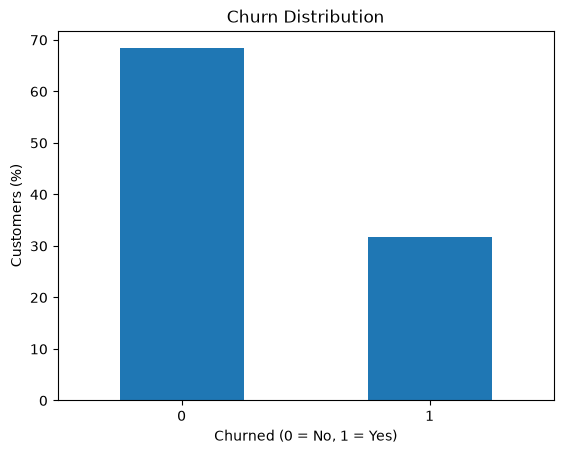

In [9]:
ax = churn_pct.plot(kind="bar")
ax.set_title("Churn Distribution")
ax.set_xlabel("Churned (0 = No, 1 = Yes)")
ax.set_ylabel("Customers (%)")
plt.xticks(rotation=0)
plt.show()

### Interpret the churn rate

Answer in business language:

1. What is the churn rate?
the churn rate 31.67%
2. What does that percentage mean?
this means that 31.7% has churnt to a different company.
3. If the company had 10,000 comparable customers and the same rate continued, approximately how many would churn?
that would mean that 3167 customers would churn.
4. Is churn the majority or minority outcome?
Its the minority because it's less then 50% of the total customers.
5. Can you conclude from this dataset alone that the churn rate is commercially unacceptable? Explain what additional context would be needed.
I think that more than 30% of your customers is unhappy is unacceptable.
you should at least bring this back to 15%

# 5. Why actual churners can be missed

Suppose a future model predicts **“No churn” for every customer**.

Because most customers do not churn, that rule can still achieve apparently reasonable accuracy.

Calculate the accuracy of this deliberately poor rule.

In [10]:
naive_accuracy = (df["Churned"] == 0).mean()
actual_churners = (df["Churned"] == 1).sum()

print(f"Naive accuracy: {naive_accuracy:.2%}")
print(f"Actual churners: {actual_churners}")
print(f"Actual churners missed: {actual_churners}")
print("Share of actual churners missed: 100%")

Naive accuracy: 68.33%
Actual churners: 95
Actual churners missed: 95
Share of actual churners missed: 100%


### Discuss

- Why is **68.33% accuracy** misleading in this example?
because this percentage are the customers that will not churn.
- What happens to the 95 actual churners?
they will go to a different provider.
- What could the business lose if customers who will churn are classified as non-churners?
they will lose possible revenue because they cant save their customers.
- Why will we eventually need to look beyond accuracy when evaluating a churn model?
because the model is not god. it will make mistakes. 

A missed actual churner is called a **false negative**. You do not need to calculate model metrics today; the purpose is to understand the business risk created by the target distribution.

# 6. Explore relationships with churn

For each analysis:
1. describe what you observe;
2. compare churners and non-churners;
3. connect the observation to the business problem;
4. do **not** claim causation.

In [11]:
# Numerical variables: compare churners and non-churners
numeric_vars = ["Age", "Tenure_Months", "Annual_Spend", "Customer_Service_Calls"]
df.groupby("Churned")[numeric_vars].agg(["mean", "median"]).round(2)

Age        Tenure_Months        Annual_Spend           \
          mean median          mean median         mean   median   
Churned                                                            
0        42.94   43.0         31.99   32.0      4298.71  4261.14   
1        44.14   44.0         26.61   28.0      3607.48  3413.65   

        Customer_Service_Calls         
                          mean median  
Churned                                
0                         3.70    3.0  
1                         4.65    5.0

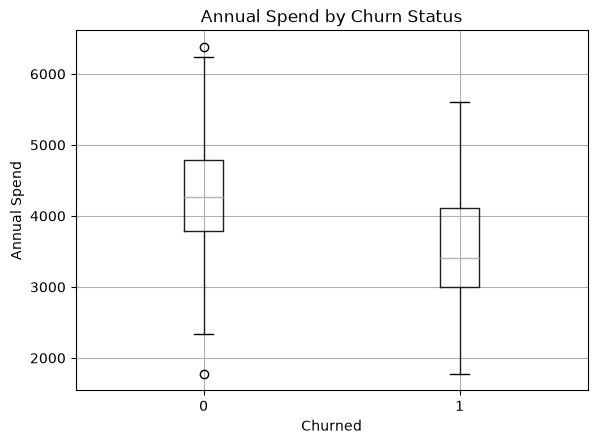

In [12]:
# Annual spend
df.boxplot(column="Annual_Spend", by="Churned")
plt.title("Annual Spend by Churn Status")
plt.suptitle("")
plt.xlabel("Churned")
plt.ylabel("Annual Spend")
plt.show()

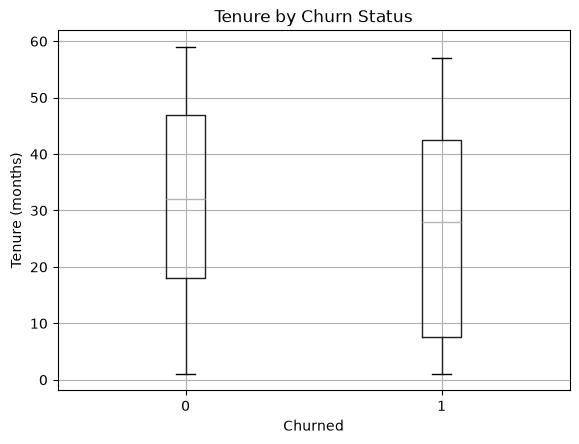

In [13]:
# Tenure
df.boxplot(column="Tenure_Months", by="Churned")
plt.title("Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churned")
plt.ylabel("Tenure (months)")
plt.show()

,customers,churn_rate,churn_rate_pct
Customer_Service_Calls,,,
0,9,0.111111,11.111111
1,28,0.178571,17.857143
2,43,0.255814,25.581395
3,60,0.316667,31.666667
4,50,0.160000,16.000000
5,37,0.513514,51.351351
6,25,0.360000,36.000000
7,25,0.480000,48.000000
8,11,0.545455,54.545455


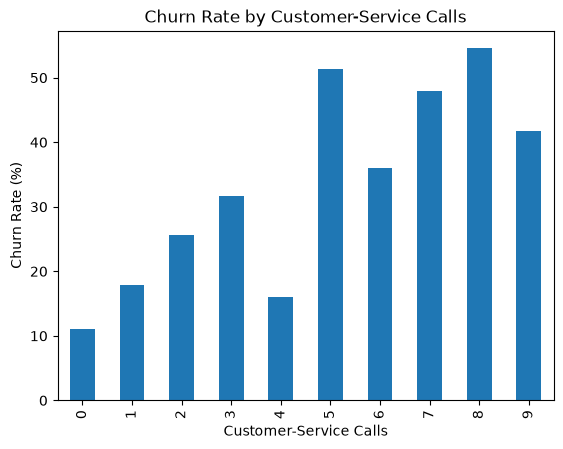

In [14]:
# Service calls
service = df.groupby("Customer_Service_Calls").agg(
    customers=("Customer_ID","count"),
    churn_rate=("Churned","mean")
)
service["churn_rate_pct"] = service["churn_rate"] * 100
display(service)

service["churn_rate_pct"].plot(kind="bar")
plt.title("Churn Rate by Customer-Service Calls")
plt.xlabel("Customer-Service Calls")
plt.ylabel("Churn Rate (%)")
plt.show()

In [15]:
# Categorical variables
for variable in ["Gender", "Region", "Promo_Used"]:
    summary = df.groupby(variable).agg(
        customers=("Customer_ID","count"),
        churn_rate=("Churned","mean")
    )
    summary["churn_rate_pct"] = summary["churn_rate"] * 100
    print(f"\n--- {variable} ---")
    display(summary.round(3))


--- Gender ---


,customers,churn_rate,churn_rate_pct
Gender,,,
Female,162,0.346,34.568
Male,138,0.283,28.261



--- Region ---


,customers,churn_rate,churn_rate_pct
Region,,,
East,68,0.426,42.647
North,90,0.256,25.556
South,65,0.338,33.846
West,77,0.273,27.273



--- Promo_Used ---


,customers,churn_rate,churn_rate_pct
Promo_Used,,,
0,113,0.319,31.858
1,187,0.316,31.551


### Evidence-based findings

Write at least **three findings**.

For each finding use this structure:

**Evidence:** What did you observe?  
**Interpretation:** What might this mean for the business?  
**Caution:** What can you *not* conclude from this relationship?

1. The chance of churning is a bit higher with females than it is with males, also the East dominates in rates of churning. The number of phone calls enlarges the chance of people churning, with 4 calls being an acception.
2. This means that the chance of people churning can be predicted, this also means the company can take several steps in certain directions to ensure people will not churn.
3. what the biggest pain point is regarding the relationships to customers who churn.

# 7. Data-quality understanding

Data Understanding also asks whether the available data appears suitable and trustworthy.

**Observe only. Do not fix anything.**

In [16]:
quality = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(dropna=False)
})
display(quality)

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Customer_ID values:", df["Customer_ID"].duplicated().sum())

,data_type,missing_values,unique_values
Customer_ID,int64,0,300
Age,int64,0,51
Gender,str,0,2
Region,str,0,4
Tenure_Months,int64,0,59
Annual_Spend,float64,0,300
Promo_Used,int64,0,2
Customer_Service_Calls,int64,0,10
Churned,int64,0,2


Exact duplicate rows: 0
Duplicate Customer_ID values: 0


In [17]:
for col in ["Gender", "Region", "Promo_Used", "Churned"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


Gender:
Gender
Female    162
Male      138
Name: count, dtype: int64

Region:
Region
North    90
West     77
East     68
South    65
Name: count, dtype: int64

Promo_Used:
Promo_Used
1    187
0    113
Name: count, dtype: int64

Churned:
Churned
0    205
1     95
Name: count, dtype: int64


In [18]:
df[["Age", "Tenure_Months", "Annual_Spend", "Customer_Service_Calls"]].agg(["min","max","mean","median"]).T

,min,max,mean,median
Age,18.00,69.00,43.320000,43.500
Tenure_Months,1.00,59.00,30.283333,29.500
Annual_Spend,1772.29,6380.96,4079.818533,4094.535
Customer_Service_Calls,0.00,9.00,4.000000,4.000


### Data-quality findings

Record what you found. Do **not** propose or execute cleaning code.

| Observation / concern | Variable(s) | Evidence | Why it could matter |
|---|---|---|---|
| I think all the data is valid. |  |  |  |
|there is a big spread of data.  |the regions and sex aren't evenly spread  |  |because this could cause faults in the data  |
|  |  |  |  |

# 8. Final Data Understanding conclusion

Complete this section in Markdown.

### A. Churn situation
- Churn rate: 31.67%
- Number of churners:95
- Business meaning:31.67% of the customers has changed to a different provider.

### B. Risk of missing churners
Explain why a seemingly acceptable accuracy can still be poor for the churn problem.

Because there is a possibility you lose customers that could have been saved with a discount.

### C. Three strongest observations
1. standard deviation of customer ID is not relevant for the company
2. there is a relitivaly wide range of age
3. there is a relitivaly wide range of tenure months

### D. Data-quality observations
| Observation / concern | Variable(s) | Evidence | Why it could matter |
|---|---|---|---|
| I think all the data is valid. |  |  |  |
|there is a big spread of data.  |the regions and sex aren't evenly spread  |  |because this could cause faults in the data  |
|  |  |  |  |

### E. Limitations
The reason of churning is missing.
And also the financial impact is missing

### F. Questions to carry forward
the next step will be modeling and then you evaluating and deployment

---

## End of this week's work

**Stop here.**

This week is **Data Understanding only**.  
Next week you will use these findings when you combine **Data Preparation and Modelling**.